# Weather Hazard Category · XGBoost Classifier

**36120 Advanced Machine Learning Application** · Assessment Task 2 · Weather Intelligence (Open-Meteo, Sydney)

*Experiment notebook · predicts WHC exactly +7 days ahead*

This notebook develops the **XGBoost Classifier** model for the **Weather Hazard Category (WHC)**: pipeline stages 1-2, using the leakage-audited feature matrix produced by the preprocessing notebook.

### Student details

| | |
|:--|:--|
| **Student name** | Juan Vargas T. |
| **Student ID** | 25945320 |
| **Subject** | 36120 Advanced Machine Learning Application |
| **Assessment** | AT2 · Weather Intelligence |
| **GitHub** | [Sebas102507](https://github.com/Sebas102507) |

## Overview

### Hypothesis

Gradient-boosted trees will achieve the **highest validation macro F1 of the five hazard
experiments**, because boosting focuses successive rounds on the examples currently misclassified,
which on an imbalanced target are the rare hazard days.

The competing possibility is stated plainly: with only a few dozen minority-class training days,
boosting has little to focus on. Walk-forward CV over four validation years tests whether any
advantage holds beyond a single year.

### Design

| Choice | Value | Reason |
|:--|:--|:--|
| Algorithm | `XGBClassifier`, `hist`, softmax objective | Strong tabular performance |
| Imbalance | Balanced sample weights, tuned on and off | Whether re-weighting helps is an empirical question |
| Scaling | None | Trees split on thresholds, so scale is irrelevant |
| Strategy | One classifier for the single +7 day horizon | Matches the deployed artefact layout |
| Selection | Optuna on walk-forward CV, all features | Section 5 |
| Objective | validation **macro F1** (higher is better), averaged over the walk-forward folds | Used for every comparison |

### Where this notebook sits in the pipeline

| Stage | What happens | Where |
|:-:|:--|:--|
| 1–2 | Baselines, ablation and hyperparameter tuning on all features | **This notebook** |
| 3 | Shortlist the best tuned algorithms | Comparison notebook |
| 4 | Feature selection for the shortlist, then a short re-tune | Comparison notebook |
| 5–6 | Choose the champion; refit it on all development data | Comparison notebook |
| 7 | Score the champion once on the test split (2025) | Comparison notebook |
| 8 | Deploy with drift monitoring | Promotion + API |

Every score in this notebook is a **walk-forward cross-validation** average: the development split
(2016–2024) is divided into four expanding-window folds that validate on 2021, 2022, 2023 and 2024
in turn, with the embargo as a gap. A setting therefore has to work across four years, not one. The
test split is never loaded here.

### Workflow

All ten experiment notebooks run the same code from `nucleus_ml.weather.Experiment`, so their results are directly comparable. **Only the model specification in section 1 differs between notebooks.**

| # | Step | Purpose |
|:-:|:--|:--|
| 1 | Model specification | The only algorithm-specific cell |
| 2 | Data and folds | The development split and its walk-forward folds |
| 3 | Baselines | Stage 1: the floor every model must clear |
| 4 | Feature-family ablation | What each block of engineered features contributes |
| 5 | Hyperparameter tuning | Stage 2: Optuna, scored by walk-forward CV on all features |
| 6 | Cross-validated results | The model against its default and the baselines |
| 7 | Feature importance | Which features the model relies on |
| 8 | Generalisation check | Training vs validation performance |
| 9 | Save the experiment bundle | Model, CV results and specification |
| 10 | Conclusions | What to carry into the report |

---
## 0. Setup

Imports, the experiment's identity and the task definition. Everything else comes from the project package.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from xgboost import XGBClassifier

from nucleus_ml import CategoricalParameter, FloatParameter, IntParameter
from nucleus_ml import weather as wx

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)

TASK = "weather_hazard"
EXPERIMENT = "whc_xgboost"
ALGORITHM = "XGBoost Classifier"
VERBOSE = 1  # 0 = results only, 1 = progress + every Optuna trial, 2 = every model fit
N_TRIALS = 30  # Optuna trials per target (each trial fits one model per fold)

task = wx.load_task(TASK)
print(f"{task.target_name} | {ALGORITHM} | {len(task.feature_columns)} features | "
      f"targets: {task.target_columns}")

Weather Hazard Category | XGBoost Classifier | 105 features | targets: ['whc_t7']


---
## 1. Model specification

This is the **only algorithm-specific cell**. It creates the experiment from the estimator class, which the package builds (seeding it and, where requested, scaling the features), so no helper function is needed. It also sets `default_params` (the untuned reference), a cheaper `ablation_params` and the `search_space`, written with the `nucleus_ml` parameter classes.

XGBoost has no `class_weight` option for multiclass problems. Instead, the `balance_classes`
setting makes the package supply balanced sample weights at fit time (via
`wx.OrdinalClassifier`, which lives in the package so the saved model loads anywhere). It is the
parameter to watch: it encodes the trade-off between missed hazards and false alarms.

In [2]:
DEFAULT_PARAMS = {"n_estimators": 400, "learning_rate": 0.05, "max_depth": 4,
                  "min_child_weight": 3, "subsample": 0.8, "colsample_bytree": 0.6,
                  "reg_lambda": 1.0, "reg_alpha": 0.0, "balance_classes": True}

exp = wx.Experiment(
    task,
    name=EXPERIMENT,
    algorithm=ALGORITHM,
    verbose=VERBOSE,
    estimator=XGBClassifier,
    fixed={"tree_method": "hist", "objective": "multi:softprob", "n_jobs": -1, "verbosity": 0},
    default_params=DEFAULT_PARAMS,
    ablation_params={**DEFAULT_PARAMS, "n_estimators": 150, "learning_rate": 0.08},
    search_space={
        "n_estimators": IntParameter(150, 700, step=50),
        "learning_rate": FloatParameter(0.01, 0.3, log=True),
        "max_depth": IntParameter(2, 8),
        "min_child_weight": FloatParameter(0.5, 20.0, log=True),
        "subsample": FloatParameter(0.5, 1.0),
        "colsample_bytree": FloatParameter(0.3, 1.0),
        "reg_lambda": FloatParameter(0.5, 50.0, log=True),
        "reg_alpha": FloatParameter(1e-3, 5.0, log=True),
        "balance_classes": CategoricalParameter([True, False]),
    },
)

[whc_xgboost] loaded 9,095 development rows; 4 walk-forward folds; 105 features; metric macro_f1 (higher is better)


---
## 2. Data and folds

Only the **development split** (`train`, 2016–2024) is loaded. The table lists the
walk-forward folds: each trains on every year before its validation year, with the
embargo between them.

> The preprocessing notebook already applied the chronological split, the warm-up
> filter and the embargo before the test period. Nothing is shuffled here.

In [3]:
exp.data_summary()

,train_start,train_end,validate_start,validate_end,train_rows,validate_rows,validate_Low Risk,validate_Moderate Risk,validate_High Risk,validate_Extreme Risk
fold,,,,,,,,,,
1,2000-01-31,2020-12-18,2020-12-26,2021-12-25,7628,365,172.000,178.000,14.000,1.000
2,2000-01-31,2021-12-18,2021-12-26,2022-12-25,7993,365,150.000,189.000,24.000,2.000
3,2000-01-31,2022-12-18,2022-12-26,2023-12-25,8358,365,209.000,146.000,10.000,0.000
4,2000-01-31,2023-12-18,2023-12-26,2024-12-24,8723,365,167.000,183.000,15.000,0.000


---
## 3. Baselines

Three naive forecasts, refitted on the training years of every fold and scored on its
validation year (the table shows the mean over the folds):

| Baseline | Rule | What it knows |
|:--|:--|:--|
| **Majority class** | Always predict the most common class | Nothing but the class balance |
| **Persistence** | The class in 7 days equals today's class (from today's WHI) | The current weather |
| **Seasonal mode** | The most common class for that month | The season |

The majority-class rule scores a high *accuracy* but a low *macro F1*, which is exactly why
accuracy is not used to select models for this imbalanced target.

In [4]:
exp.run_baselines()

[whc_xgboost] baseline majority_class  whc_t7: mean macro_f1 = 0.1612
[whc_xgboost] baseline persistence     whc_t7: mean macro_f1 = 0.2546
[whc_xgboost] baseline seasonal_mode   whc_t7: mean macro_f1 = 0.2742


accuracy  balanced_accuracy  macro_f1  weighted_f1  \
target model                                                                
whc_t7 majority_class     0.478              0.292     0.161        0.311   
       persistence        0.468              0.295     0.255        0.468   
       seasonal_mode      0.541              0.329     0.274        0.527   

                       mean_ordinal_error  
target model                               
whc_t7 majority_class               0.569  
       persistence                  0.577  
       seasonal_mode                0.486

---
## 4. Feature-family ablation

Feature families are added **one at a time**, starting from persistence alone, and the model is cross-validated at each step with `ablation_params`. This *measures* what each block of engineering contributes; choosing features happens later, in the comparison notebook. Scores are mean macro F1 over the folds.

[whc_xgboost] ablation: 9 feature sets x 1 target(s) x 4 folds
[whc_xgboost] ablation persistence only (whi)              whc_t7: macro_f1 = 0.2183 (1 features)
[whc_xgboost] ablation + same_day_observations             whc_t7: macro_f1 = 0.2501 (6 features)
[whc_xgboost] ablation + same_day_indices                  whc_t7: macro_f1 = 0.2511 (17 features)
[whc_xgboost] ablation + lags                              whc_t7: macro_f1 = 0.2571 (49 features)
[whc_xgboost] ablation + rolling_statistics                whc_t7: macro_f1 = 0.2644 (89 features)
[whc_xgboost] ablation + rolling_precipitation             whc_t7: macro_f1 = 0.2546 (93 features)
[whc_xgboost] ablation + rolling_gusts                     whc_t7: macro_f1 = 0.2549 (97 features)
[whc_xgboost] ablation + deltas                            whc_t7: macro_f1 = 0.2559 (103 features)
[whc_xgboost] ablation + seasonal                          whc_t7: macro_f1 = 0.2597 (105 features)


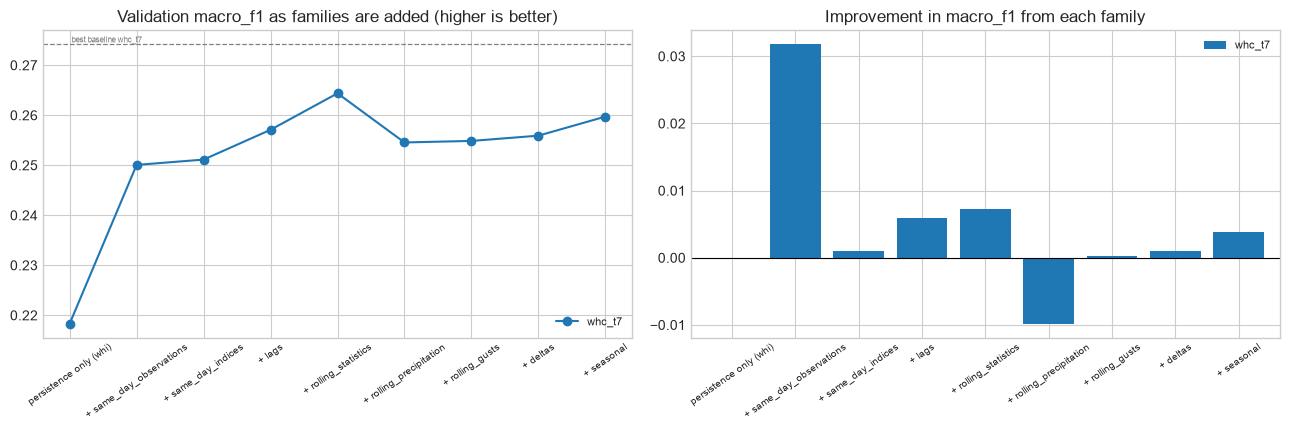

target,whc_t7,n_features
config,,
persistence only (whi),0.218,1
+ same_day_observations,0.250,6
+ same_day_indices,0.251,17
+ lags,0.257,49
+ rolling_statistics,0.264,89
+ rolling_precipitation,0.255,93
+ rolling_gusts,0.255,97
+ deltas,0.256,103
+ seasonal,0.260,105


In [5]:
ablation = exp.run_ablation()
plt.show()
ablation

---
## 5. Hyperparameter tuning

Optuna (seeded TPE sampler) searches the space defined in section 1, **on all
features**. Every trial is cross-validated on the four folds and scored by its
mean, so the search cannot overfit to one year. Each target is tuned separately.
The plots show the search history and which settings mattered most.

In [6]:
exp.tune(n_trials=N_TRIALS)

[whc_xgboost] tuning whc_t7: 30 trials x 4 folds


/Users/juanvargas/UTS/3rd Semester/AdvanceML/Assignment_2/36120-26SP-AT2-25945320-experiments/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[I 2026-09-19 17:42:54,594] A new study created in memory with name: whc_xgboost_whc_t7
[I 2026-09-19 17:42:58,476] Trial 0 finished with value: 0.22960813157690763 and parameters: {'n_estimators': 150, 'learning_rate': 0.031916200230628806, 'max_depth': 2, 'min_child_weight': 0.8535974404936146, 'subsample': 0.6365974786973265, 'colsample_bytree': 0.9206689385376495, 'reg_lambda': 0.6802852507039446, 'reg_alpha': 0.013787133221513578, 'balance_classes': True}. Best is trial 0 with value: 0.22960813157690763.
[I 2026-09-19 17:43:28,748] Trial 1 finished with value: 0.25486642285166233 and parameters: {'n_estimators': 300, 'learning_rate': 0.29099762548328467

[whc_xgboost] best whc_t7: mean macro_f1 = 0.2584 (568s)


,cv_macro_f1,trials,best_params
target,,,
whc_t7,0.258,30,"{'n_estimators': 500, 'learning_rate': 0.04238..."


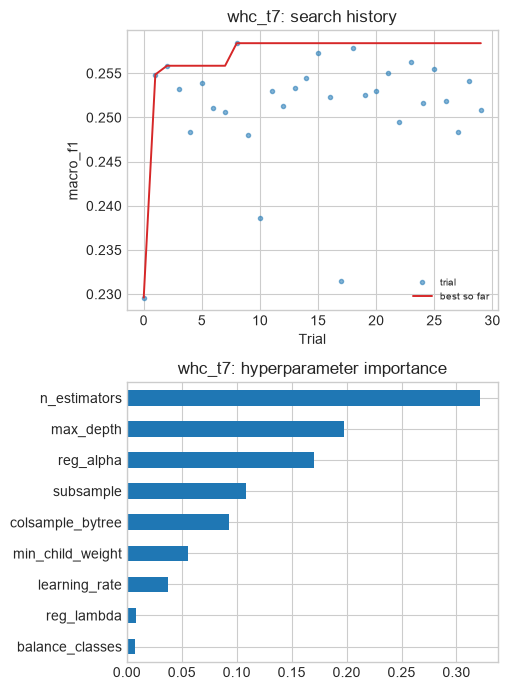

In [7]:
exp.plot_search()
plt.show()

---
## 6. Cross-validated results

The chosen configuration is cross-validated again and compared with the untuned `default` and every baseline, all on the same folds. `gain_of_model` is positive when the model beats that row. The plot shows the **out-of-fold predictions**: every validation year predicted by a model that never saw it.

Read the **confusion matrix** as well as the headline score: a model that almost never predicts
the rare classes has not learned to flag hazardous days, whatever its macro F1. The printed
boundary summary shows how many errors sit within a few WHI points of a class threshold; those are
threshold effects rather than genuine misses.

In [8]:
exp.assess()

[whc_xgboost] assess whc_t7: tuned mean macro_f1 = 0.2584 (best baseline 0.2742)


accuracy  balanced_accuracy  macro_f1  weighted_f1  \
target model                                                                
whc_t7 default            0.512              0.313     0.262        0.502   
       majority_class     0.478              0.292     0.161        0.311   
       persistence        0.468              0.295     0.255        0.468   
       seasonal_mode      0.541              0.329     0.274        0.527   
       tuned              0.477              0.299     0.258        0.482   

                       mean_ordinal_error  train_macro_f1  gain_of_model  
target model                                                              
whc_t7 default                      0.514           0.888         -0.003  
       majority_class               0.569             NaN          0.097  
       persistence                  0.577             NaN          0.004  
       seasonal_mode                0.486             NaN         -0.016  
       tuned                        0.573           0.763          0.000

Misclassification vs class boundaries: {'misclassified': 764, 'of_days': 1460, 'median_distance_to_boundary': 5.152499999999998, 'share_within_5_points': 0.4895287958115183}


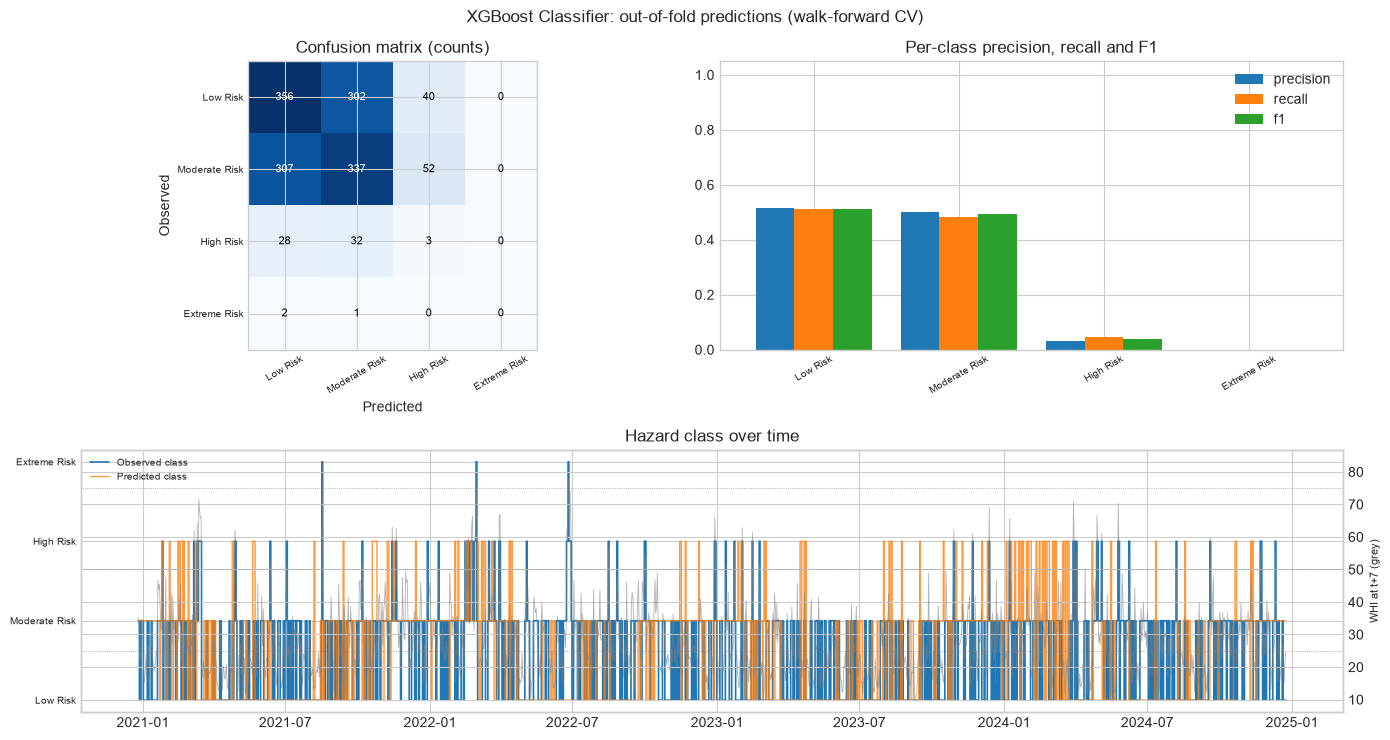

In [9]:
exp.plot_validation()
plt.show()

---
## 7. Feature importance

Tree ensembles report **impurity-based importance** directly from the fitted model. Comparing horizons is informative: features that rise in rank from *t*+1 to *t*+3 carry genuine forecast signal rather than persistence.

> Importance is measured on the last fold's model and validation year (2024). Correlated features share importance, so the ablation in section 4 is the better guide to what can be removed.

[whc_xgboost] computing feature importance (permutation importance can take a while)


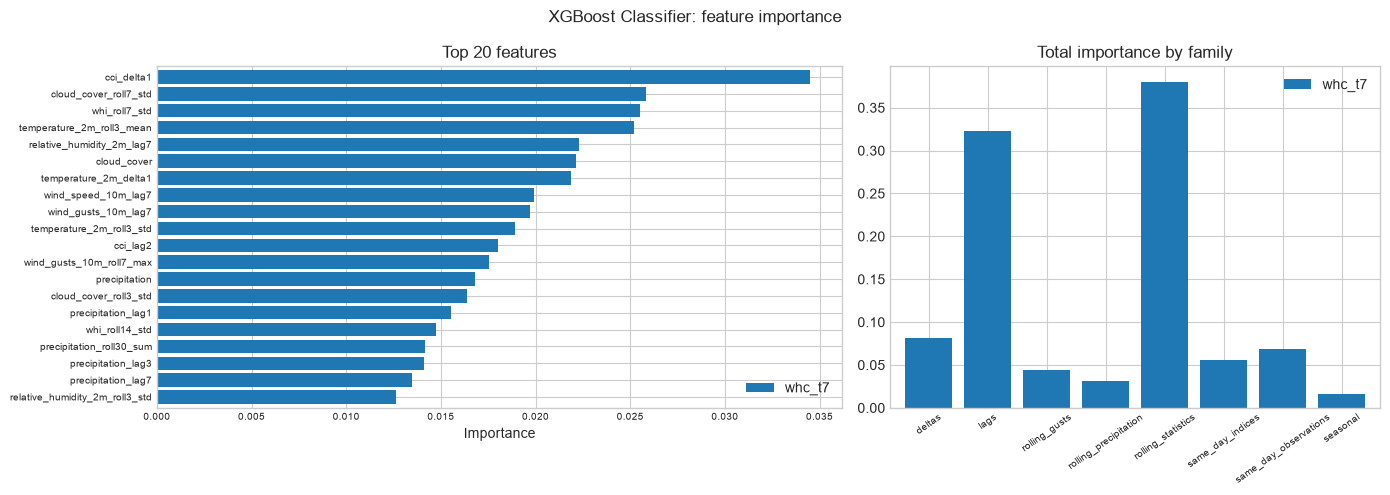

,whc_t7
deltas,0.081
lags,0.323
rolling_gusts,0.044
rolling_precipitation,0.031
rolling_statistics,0.380
same_day_indices,0.056
same_day_observations,0.068
seasonal,0.016


In [10]:
family_importance = exp.importance()
plt.show()
family_importance

---
## 8. Generalisation check

Mean training and validation scores over the folds. A small gap means the model
generalises; a large gap means it memorises the training years.

In [11]:
exp.generalisation()

,train_macro_f1,validation_macro_f1,validation_minus_train
target,,,
whc_t7,0.763,0.258,-0.505


---
## 9. Save the experiment bundle

The chosen configuration is refitted on **all development data** and saved to
`models/weather_hazard/experiments/whc_xgboost/`:

| File | Contents |
|:--|:--|
| `whc_xgboost_h<horizon>.joblib` | The model, one per horizon |
| `metadata.json` | Settings, features, importance and the cross-validated scores |
| `manifest.json` | File list and the feature column order |
| `spec.joblib` | The specification and tuned settings, which the comparison notebook uses to rebuild this experiment |

In [12]:
exp.export()

[whc_xgboost] final fit whc_t7: 9,095 rows, 105 features
Saved bundle: models/weather_hazard/experiments/whc_xgboost


PosixPath('/Users/juanvargas/UTS/3rd Semester/AdvanceML/Assignment_2/36120-26SP-AT2-25945320-experiments/models/weather_hazard/experiments/whc_xgboost')

---
## 10. Conclusions

- **Read the confusion matrix, not only the headline.** A macro F1 above the baselines while the
  rare classes are almost never predicted means the service still cannot flag a hazardous day.
- **Re-weighting.** The search tested balanced and unweighted fitting; the winner encodes the
  trade-off between missed hazards and false alarms.
- **Boundary errors.** A high share of errors within 5 WHI points of a threshold argues for
  predicting WHI and applying the thresholds afterwards, a concrete idea for future work.

> If this algorithm is shortlisted, the comparison notebook selects its feature families with walk-forward cross-validation and briefly re-tunes its settings on the chosen features.

> The test split has still not been used. It is scored exactly once, in the `whc_comparison` notebook, after the champion has been chosen.